# Predictive Process Monitoring: live demo
**Question:** a patient with suspected sepsis is in the hospital right now. Based on what has happened *so far*, will they end up in intensive care (ICU)?

Data: *Sepsis Cases* event log (Mannhardt 2016, 4TU.ResearchData), 1,049 patients / 15,214 events.
Pipeline as in Teinemaa et al. (2019): **prefixes, then encoding, then classifier, then AUC per prefix length**.

In [ ]:
# first time only:  pip install pandas scikit-learn xgboost matplotlib
import pandas as pd, numpy as np, matplotlib.pyplot as plt, time, warnings
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
t_start = time.time()

## 1. The event log: one row per event

In [ ]:
log = pd.read_csv("sepsis_cases.csv", parse_dates=["timestamp"])
log = log.sort_values(["case_id", "timestamp"], kind="stable").reset_index(drop=True)
print(log["case_id"].nunique(), "cases,", len(log), "events,", log["activity"].nunique(), "activities")
log[log.case_id == "A"][["case_id", "activity", "resource", "timestamp", "crp", "leucocytes", "lacticacid"]]

1049 cases, 15214 events, 16 activities


,case_id,activity,resource,timestamp,crp,leucocytes,lacticacid
0,A,ER Registration,A,2014-10-22 11:15:41,NaN,NaN,NaN
1,A,Leucocytes,B,2014-10-22 11:27:00,NaN,9.6,NaN
2,A,CRP,B,2014-10-22 11:27:00,210.0,NaN,NaN
3,A,LacticAcid,B,2014-10-22 11:27:00,NaN,NaN,2.2
4,A,ER Triage,C,2014-10-22 11:33:37,NaN,NaN,NaN
5,A,ER Sepsis Triage,A,2014-10-22 11:34:00,NaN,NaN,NaN
6,A,IV Liquid,A,2014-10-22 14:03:47,NaN,NaN,NaN
7,A,IV Antibiotics,A,2014-10-22 14:03:47,NaN,NaN,NaN
8,A,Admission NC,D,2014-10-22 14:13:19,NaN,NaN,NaN
9,A,CRP,B,2014-10-24 09:00:00,1090.0,NaN,NaN


## 2. Label: does the case reach `Admission IC`?
The label must be predicted **before** it happens, so every case is cut just before its first `Admission IC`.
We also drop the discharge events (`Release A–E`, `Return ER`): they happen after the stay and would give the answer away.

In [ ]:
log["label"] = log.groupby("case_id")["activity"].transform(lambda s: int((s == "Admission IC").any()))
log["pos"] = log.groupby("case_id").cumcount()
first_ic = log[log.activity == "Admission IC"].groupby("case_id")["pos"].min()
log = log[~(log.case_id.map(first_ic).notna() & (log.pos >= log.case_id.map(first_ic)))]
log = log[~log.activity.str.startswith("Release") & (log.activity != "Return ER")].copy()

# case attributes (static) are recorded on the first event, ER Registration
STATIC = [c for c in log.columns if c.startswith(("diagnostic", "sirscrit")) or c in
          ["age", "disfuncorg", "hypotensie", "hypoxie", "infectionsuspected", "infusion", "oligurie"]]
static = log.groupby("case_id")[STATIC].first().astype(float)
labels = log.groupby("case_id")["label"].first()
print(f"ICU cases: {labels.sum()} of {len(labels)} ({labels.mean():.0%})")

ICU cases: 110.0 of 1049 (10%)


## 3. Temporal train/test split
Train on the patients who arrived first (80%), test on the later ones, as in real life.

In [ ]:
starts = log.groupby("case_id")["timestamp"].min().sort_values()
train_ids = set(starts.index[: int(0.8 * len(starts))])
log["t_since_start_h"] = (log.timestamp - log.groupby("case_id").timestamp.transform("min")).dt.total_seconds() / 3600
log["pos"] = log.groupby("case_id").cumcount()
print("train cases:", len(train_ids), " test cases:", len(starts) - len(train_ids))

train cases: 839  test cases: 210


## 4. Prefixes and three encodings
A prefix of length k = the first k events of a case. Every prefix gets a **fixed-length feature vector**:
* **last state**: only the latest event (activity, resource, last lab values)
* **aggregation**: counts of every activity/resource plus mean/max of the lab values (order is lost)
* **index**: activity and resource at every position 1..k (lossless, so one model per prefix length)

Every vector also gets the static case attributes and the elapsed time.

In [ ]:
ACTS = sorted(log.activity.unique()); RES = sorted(log.resource.unique()); LABS = ["crp", "leucocytes", "lacticacid"]

def prefix_log(k):
    p = log[log.pos < k]
    n = p.groupby("case_id").size()
    return p[p.case_id.isin(n[n == k].index)]          # only cases that really have >= k events

def enc_last(p):
    last = p.groupby("case_id").last()
    X = pd.get_dummies(last[["activity", "resource"]]).reindex(
        columns=[f"activity_{a}" for a in ACTS] + [f"resource_{r}" for r in RES], fill_value=0)
    X[[f"last_{l}" for l in LABS]] = p.groupby("case_id")[LABS].last().values   # last observed lab value
    return X

def enc_agg(p):
    X = pd.crosstab(p.case_id, p.activity).reindex(columns=ACTS, fill_value=0).add_prefix("count_")
    X = X.join(pd.crosstab(p.case_id, p.resource).reindex(columns=RES, fill_value=0).add_prefix("res_"))
    g = p.groupby("case_id")[LABS]
    return X.join(g.mean().add_suffix("_mean")).join(g.max().add_suffix("_max"))

def enc_index(p):
    w = p.pivot(index="case_id", columns="pos", values=["activity", "resource"])
    w.columns = [f"{a}_{int(i)+1}" for a, i in w.columns]
    return pd.get_dummies(w).astype(int)

USE_CASE_ATTRIBUTES = True        # <- live experiment: set to False and re-run from here

def encode(p, enc):
    X = enc(p)
    if USE_CASE_ATTRIBUTES:
        X = X.join(static)
    X["elapsed_h"] = p.groupby("case_id").t_since_start_h.last()
    X["prefix_len"] = p.groupby("case_id").size()
    return X.astype(float)

# example: the same 4-event prefix of case A in all three encodings
pA = prefix_log(4); pA = pA[pA.case_id == "A"]
print(pA[["activity", "resource", "crp", "leucocytes"]].to_string(), "\n")
for name, enc in [("last state", enc_last), ("aggregation", enc_agg), ("index", enc_index)]:
    v = enc(pA).iloc[0].astype(float); v = v[v != 0].dropna()
    print(f"{name:12s}", {k: round(float(x), 1) for k, x in v.items()})

          activity resource    crp  leucocytes
0  ER Registration        A    NaN         NaN
1       Leucocytes        B    NaN         9.6
2              CRP        B  210.0         NaN
3       LacticAcid        B    NaN         NaN 

last state   {'activity_LacticAcid': 1.0, 'resource_B': 1.0, 'last_crp': 210.0, 'last_leucocytes': 9.6, 'last_lacticacid': 2.2}
aggregation  {'count_CRP': 1.0, 'count_ER Registration': 1.0, 'count_LacticAcid': 1.0, 'count_Leucocytes': 1.0, 'res_A': 1.0, 'res_B': 3.0, 'crp_mean': 210.0, 'leucocytes_mean': 9.6, 'lacticacid_mean': 2.2, 'crp_max': 210.0, 'leucocytes_max': 9.6, 'lacticacid_max': 2.2}
index        {'activity_1_ER Registration': 1.0, 'activity_2_Leucocytes': 1.0, 'activity_3_CRP': 1.0, 'activity_4_LacticAcid': 1.0, 'resource_1_A': 1.0, 'resource_2_B': 1.0, 'resource_3_B': 1.0, 'resource_4_B': 1.0}


## 5. Train and evaluate
* **last state** and **aggregation**: one single XGBoost model over all prefix lengths (*single bucket*)
* **index**: one XGBoost model per prefix length (*prefix-length buckets*)

Evaluated with **AUC per prefix length** on the test patients (AUC 0.5 = guessing, 1.0 = perfect).

In [ ]:
K = range(1, 9)                     # most ICU admissions happen around event 9
prefixes = {k: prefix_log(k) for k in K}
model = lambda: XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, random_state=0, n_jobs=-1)

def split(X):
    tr = X.index.isin(train_ids)
    return X[tr], labels[X.index[tr]], X[~tr], labels[X.index[~tr]]

results = {}
for name, enc in [("last state", enc_last), ("aggregation", enc_agg)]:
    X = pd.concat([encode(prefixes[k], enc).set_index(prefixes[k].groupby("case_id").size().index + f"|{k}")
                   for k in K])
    X.index = X.index.str.split("|").str[0]
    Xtr, ytr, Xte, yte = split(X)
    m = model().fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    results[name] = {k: roc_auc_score(yte[Xte.prefix_len == k], p[Xte.prefix_len.values == k]) for k in K}
    if name == "aggregation": agg_model, agg_cols = m, X.columns

results["index"] = {}
for k in K:
    X = encode(prefixes[k], enc_index)
    Xtr, ytr, Xte, yte = split(X)
    Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)
    results["index"][k] = roc_auc_score(yte, model().fit(Xtr, ytr).predict_proba(Xte)[:, 1])

res = pd.DataFrame(results).round(3); res.index.name = "prefix length"
print(res.to_string()); print("\nmean AUC:", {k: round(float(v), 3) for k, v in res.mean().items()})
n_test = [(split(encode(prefixes[k], enc_agg))[3]) for k in K]
print("test cases per prefix length:", [len(y) for y in n_test], " of which ICU:", [int(y.sum()) for y in n_test])
print("note: only ~20 ICU patients in the test set, so differences below ~0.05 AUC are noise")

               last state  aggregation  index
prefix length                                
1                   0.779        0.775  0.800
2                   0.799        0.789  0.754
3                   0.799        0.786  0.808
4                   0.762        0.740  0.719
5                   0.772        0.747  0.790
6                   0.770        0.762  0.807
7                   0.751        0.752  0.775
8                   0.761        0.769  0.709

mean AUC: {'last state': 0.774, 'aggregation': 0.765, 'index': 0.77}


test cases per prefix length: [210, 210, 210, 201, 200, 184, 173, 169]  of which ICU: [22, 22, 22, 22, 21, 20, 19, 19]
note: only ~20 ICU patients in the test set, so differences below ~0.05 AUC are noise


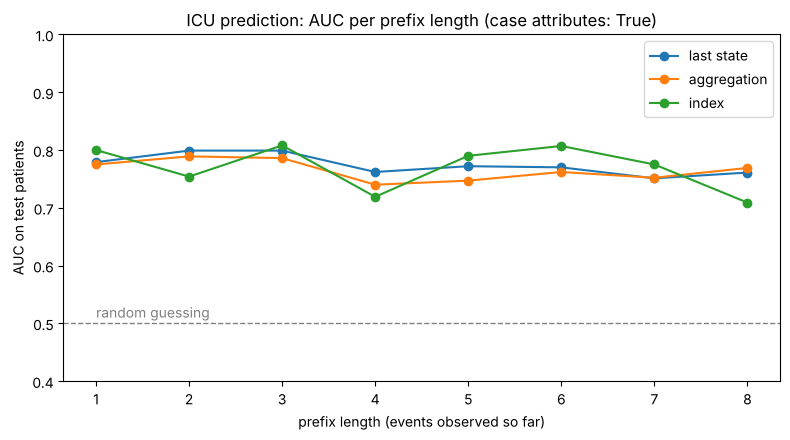

In [ ]:
ax = res.plot(marker="o", figsize=(8, 4.5), ylim=(0.4, 1.0))
ax.axhline(0.5, ls="--", c="grey", lw=1); ax.text(1, 0.51, "random guessing", color="grey")
ax.set_xlabel("prefix length (events observed so far)"); ax.set_ylabel("AUC on test patients")
ax.set_title(f"ICU prediction: AUC per prefix length (case attributes: {USE_CASE_ATTRIBUTES})")
plt.tight_layout(); plt.savefig(f"auc_by_prefix_static_{USE_CASE_ATTRIBUTES}.png", dpi=150); plt.show()

## 6. What does the model look at? (bridge to explainability)

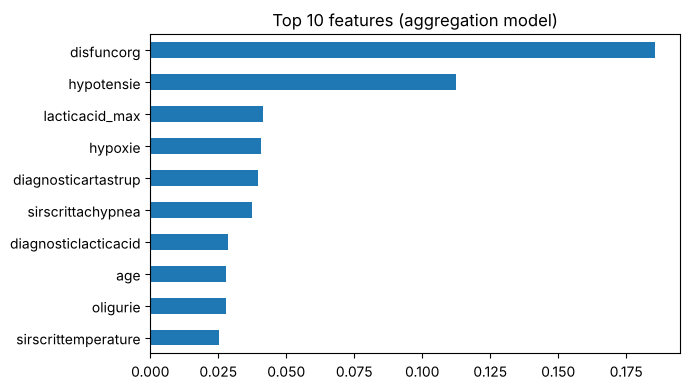

total runtime: 3.6 s


In [ ]:
imp = pd.Series(agg_model.feature_importances_, index=agg_cols).sort_values(ascending=False).head(10)
imp.sort_values().plot.barh(figsize=(7, 4), title="Top 10 features (aggregation model)"); plt.tight_layout(); plt.show()
print(f"total runtime: {time.time() - t_start:.1f} s")